In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

# ─────────────────────────────
# 1️⃣ 데이터 로드 + 상권 병합
# ─────────────────────────────
1
cluster_df = pd.read_csv(
    "../data/processed/district_clustered.csv"
)[["district", "cluster_name"]]

df = df.merge(cluster_df, on="district", how="left")

# ─────────────────────────────
# 2️⃣ 운영 중 숙소만 필터링
# ─────────────────────────────
df_model = df[
    (df["refined_status"] == "Active") &
    (df["operation_status"] == "Operating")
].copy()

# 극단값 제거
df_model = df_model[
    (df_model["l90d_avg_rate"] > 10000) &
    (df_model["l90d_occupancy"] > 0.05) &
    (df_model["l90d_occupancy"] < 0.95)
]

# ─────────────────────────────
# 3️⃣ 로그 변환 + 변수 정리
# ─────────────────────────────
df_model["log_occ"] = np.log(df_model["l90d_occupancy"])
df_model["log_adr"] = np.log(df_model["l90d_avg_rate"])
df_model["log_reviews"] = np.log(df_model["num_reviews"] + 1)

df_model["instant_book"] = df_model["instant_book"].astype(int)
df_model["superhost"] = df_model["superhost"].astype(int)

print("총 모델 데이터 수:", len(df_model))

# ─────────────────────────────
# 4️⃣ 상권별 통제변수 포함 탄력성 추정
# ─────────────────────────────
results = {}

for g in df_model["cluster_name"].dropna().unique():

    sub = df_model[df_model["cluster_name"] == g].copy()

    if len(sub) < 100:
        continue

    X_cols = [
        "log_adr",
        "rating_overall",
        "log_reviews",
        "instant_book",
        "superhost",
        "photos_count"
    ]

    X = sub[X_cols].astype(float)
    y = sub["log_occ"].astype(float)

    X = sm.add_constant(X)

    model = sm.OLS(y, X).fit()

    results[g] = {
        "n": len(sub),
        "elasticity": model.params["log_adr"],
        "p_value": model.pvalues["log_adr"],
        "R2": model.rsquared
    }

result_df = pd.DataFrame(results).T

print("\n=== 상권별 가격 탄력성 (통제변수 포함) ===")
print(result_df.sort_index())

총 모델 데이터 수: 12984

=== 상권별 가격 탄력성 (통제변수 포함) ===
                n  elasticity       p_value        R2
가격민감 외곽형   1696.0   -0.081906  1.126303e-02  0.188221
성장형 주거상권   5681.0   -0.083348  4.880440e-08  0.228181
중가 균형시장    2641.0   -0.175419  3.420683e-11  0.171067
프리미엄 관광거점  2966.0   -0.074187  3.435273e-04  0.233152


In [17]:
# result_df 인덱스를 컬럼으로 변환
result_df = result_df.reset_index()
result_df = result_df.rename(columns={"index": "cluster_name"})


# 병합
cluster_df = cluster_df.merge(
    result_df[["cluster_name", "elasticity"]],
    on="cluster_name",
    how="left"
)

# 덮어쓰기 저장
cluster_df.to_csv(
    "../data/processed/district_clustered.csv",
    index=False
)

print("클러스터 파일에 탄력성 바로 병합 완료")

클러스터 파일에 탄력성 바로 병합 완료


In [19]:
import pandas as pd
import numpy as np

# 1. 데이터 불러오기
df = pd.read_csv("../data/raw/seoul_airbnb_cleaned.csv")

# 2. Active + Operating 필터
df = df[
    (df['refined_status'] == 'Active') &
    (df['operation_status'] == 'Operating')
].copy()

results = []

# 3. 구 × 숙소유형별 반복
for (district, room_type), group in df.groupby(['district', 'room_type']):

    if len(group) < 30:
        continue

    # 분위수 계산
    p25 = np.percentile(group['ttm_avg_rate'].dropna(), 25)
    p50 = np.percentile(group['ttm_avg_rate'].dropna(), 50)
    p75 = np.percentile(group['ttm_avg_rate'].dropna(), 75)

    new_low = p25 * 0.85
    new_high = p25
    stable_low = p25
    stable_high = p50
    premium_low = p50
    premium_high = p75

    group = group.copy()
    group["price_segment"] = "기타"

    group.loc[
        (group["ttm_avg_rate"] >= new_low) &
        (group["ttm_avg_rate"] < new_high),
        "price_segment"
    ] = "신규"

    group.loc[
        (group["ttm_avg_rate"] >= stable_low) &
        (group["ttm_avg_rate"] < stable_high),
        "price_segment"
    ] = "안정"

    group.loc[
        (group["ttm_avg_rate"] >= premium_low) &
        (group["ttm_avg_rate"] <= premium_high),
        "price_segment"
    ] = "프리미엄"

    summary = group.groupby("price_segment").agg(
        count=('ttm_avg_rate', 'count'),
        avg_reviews=('num_reviews', 'mean'),
        avg_rating=('rating_overall', 'mean'),
        superhost_ratio=('superhost', 'mean'),
        avg_revpar=('ttm_revpar', 'mean')
    ).reset_index()

    total_n = len(group)
    summary["ratio"] = summary["count"] / total_n

    # 필요한 세그먼트만 추출
    seg = summary.set_index("price_segment")

    # --- 정렬 검증 ---
    try:
        revpar_valid = (
            seg.loc["프리미엄", "avg_revpar"] >
            seg.loc["안정", "avg_revpar"] >
            seg.loc["신규", "avg_revpar"]
        )

        review_valid = (
            seg.loc["프리미엄", "avg_reviews"] >
            seg.loc["안정", "avg_reviews"] >
            seg.loc["신규", "avg_reviews"]
        )

        rating_valid = (
            seg.loc["프리미엄", "avg_rating"] >=
            seg.loc["안정", "avg_rating"] >=
            seg.loc["신규", "avg_rating"]
        )

    except:
        revpar_valid = False
        review_valid = False
        rating_valid = False

    # --- 비율 왜곡 검증 ---
    distortion_flag = False

    if "신규" in seg.index and seg.loc["신규", "ratio"] < 0.05:
        distortion_flag = True

    if "프리미엄" in seg.index and seg.loc["프리미엄", "ratio"] > 0.5:
        distortion_flag = True

    if "안정" in seg.index and seg.loc["안정", "ratio"] < 0.15:
        distortion_flag = True

    structure_valid = (
        revpar_valid and
        review_valid and
        rating_valid and
        not distortion_flag
    )

    results.append({
        "district": district,
        "room_type": room_type,
        "revpar_order_valid": revpar_valid,
        "review_order_valid": review_valid,
        "rating_order_valid": rating_valid,
        "distortion_flag": distortion_flag,
        "structure_valid": structure_valid
    })

final_validation = pd.DataFrame(results)

print(final_validation.head(20))

print("\n구조 타당 비율:",
      final_validation["structure_valid"].mean())

         district     room_type  revpar_order_valid  review_order_valid  \
0       Dobong-gu   entire_home                True               False   
1   Dongdaemun-gu   entire_home                True                True   
2   Dongdaemun-gu  private_room               False               False   
3      Dongjak-gu   entire_home                True                True   
4      Dongjak-gu  private_room                True                True   
5    Eunpyeong-gu   entire_home               False               False   
6    Eunpyeong-gu  private_room               False               False   
7      Gangbuk-gu   entire_home               False               False   
8      Gangbuk-gu  private_room                True                True   
9     Gangdong-gu   entire_home                True               False   
10     Gangnam-gu   entire_home                True               False   
11     Gangnam-gu  private_room                True               False   
12     Gangseo-gu   entir

In [28]:
import pandas as pd
import numpy as np
from scipy.stats import f_oneway

# 데이터 불러오기
df = pd.read_csv("../data/raw/seoul_airbnb_cleaned.csv")

# Active + Operating 필터
df = df[
    (df['refined_status'] == 'Active') &
    (df['operation_status'] == 'Operating')
].copy()

# 결측 제거
df = df.dropna(subset=['ttm_avg_rate', 'ttm_revpar'])

# 분위수 계산 (서울 전체)
p25 = np.percentile(df['ttm_avg_rate'], 25)
p50 = np.percentile(df['ttm_avg_rate'], 50)
p75 = np.percentile(df['ttm_avg_rate'], 75)

df["segment"] = "기타"

df.loc[
    (df["ttm_avg_rate"] >= p25*0.85) &
    (df["ttm_avg_rate"] < p25),
    "segment"
] = "신규"

df.loc[
    (df["ttm_avg_rate"] >= p25) &
    (df["ttm_avg_rate"] < p50),
    "segment"
] = "안정"

df.loc[
    (df["ttm_avg_rate"] >= p50) &
    (df["ttm_avg_rate"] <= p75),
    "segment"
] = "프리미엄"

# 기타 제외
df_seg = df[df["segment"] != "기타"].copy()

# 구간별 평균 RevPAR 확인
mean_table = df_seg.groupby("segment")["ttm_revpar"].agg(
    count="count",
    mean="mean",
    std="std"
).reset_index()

print(mean_table)

# ANOVA (통계적 유의성 검증)
new = df_seg[df_seg["segment"]=="신규"]["ttm_revpar"]
stable = df_seg[df_seg["segment"]=="안정"]["ttm_revpar"]
premium = df_seg[df_seg["segment"]=="프리미엄"]["ttm_revpar"]

f_stat, p_value = f_oneway(new, stable, premium)

print("F-stat:", f_stat)
print("p-value:", p_value)

# 효과 크기 계산 (Eta Squared)
# 전체 평균
grand_mean = df_seg["ttm_revpar"].mean()

# 집단 간 제곱합 (SS_between)
ss_between = (
    len(new)*(new.mean()-grand_mean)**2 +
    len(stable)*(stable.mean()-grand_mean)**2 +
    len(premium)*(premium.mean()-grand_mean)**2
)

# 전체 제곱합 (SS_total)
ss_total = ((df_seg["ttm_revpar"] - grand_mean)**2).sum()

eta_squared = ss_between / ss_total

print("Eta Squared:", eta_squared)

  segment  count          mean           std
0      신규   1062  31158.155556  15011.021752
1      안정   3599  44298.288886  20669.507512
2    프리미엄   3600  63780.143361  31755.257734
F-stat: 891.9284751170667
p-value: 0.0
Eta Squared: 0.17764213920539287


In [29]:
# 세그먼트 생성 (가격 구간 동일)
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency

df = pd.read_csv("../data/raw/seoul_airbnb_cleaned.csv")

df = df[
    (df['refined_status'] == 'Active') &
    (df['operation_status'] == 'Operating')
].copy()

df = df.dropna(subset=['ttm_avg_rate'])

# 분위수 계산
p25 = np.percentile(df['ttm_avg_rate'], 25)
p50 = np.percentile(df['ttm_avg_rate'], 50)
p75 = np.percentile(df['ttm_avg_rate'], 75)

df["segment"] = "기타"

df.loc[(df["ttm_avg_rate"] >= p25*0.85) &
       (df["ttm_avg_rate"] < p25), "segment"] = "신규"

df.loc[(df["ttm_avg_rate"] >= p25) &
       (df["ttm_avg_rate"] < p50), "segment"] = "안정"

df.loc[(df["ttm_avg_rate"] >= p50) &
       (df["ttm_avg_rate"] <= p75), "segment"] = "프리미엄"

df_seg = df[df["segment"] != "기타"].copy()

# 전략 조건 변수 생성

# 리뷰 10건 이상
df_seg["review_10plus"] = (df_seg["num_reviews"] >= 10).astype(int)
# 평점 4.5 이상
df_seg["rating_45plus"] = (df_seg["rating_overall"] >= 4.5).astype(int)
# 평점 4.8 이상
df_seg["rating_48plus"] = (df_seg["rating_overall"] >= 4.8).astype(int)

# 슈퍼호스트
df_seg["superhost_flag"] = df_seg["superhost"].astype(int)
# 구간별 조건 충족 비율 계산
summary = df_seg.groupby("segment").agg(
    리뷰10건이상비율=("review_10plus", "mean"),
    평점4_5이상비율=("rating_45plus", "mean"),
    평점4_8이상비율=("rating_48plus", "mean"),
    슈퍼호스트비율=("superhost_flag", "mean"),
    count=("segment","count")
).reset_index()

print(summary)
# 카이제곱 검정 (통계적 유의성)



cont_table = pd.crosstab(df_seg["segment"], df_seg["review_10plus"])
chi2, p, dof, expected = chi2_contingency(cont_table)

print("리뷰10건이상 p-value:", p)


for col in ["rating_45plus", "rating_48plus", "superhost_flag"]:
    cont_table = pd.crosstab(df_seg["segment"], df_seg[col])
    chi2, p, dof, expected = chi2_contingency(cont_table)
    print(f"{col} p-value:", p)

  segment  리뷰10건이상비율  평점4_5이상비율  평점4_8이상비율   슈퍼호스트비율  count
0      신규   0.801318   0.796610   0.467985  0.513183   1062
1      안정   0.857460   0.864685   0.524590  0.552098   3599
2    프리미엄   0.874444   0.893889   0.616111  0.605000   3600
리뷰10건이상 p-value: 1.584916913101394e-08
rating_45plus p-value: 1.0904083452590747e-15
rating_48plus p-value: 1.571756667328648e-22
superhost_flag p-value: 1.0793680584814489e-08


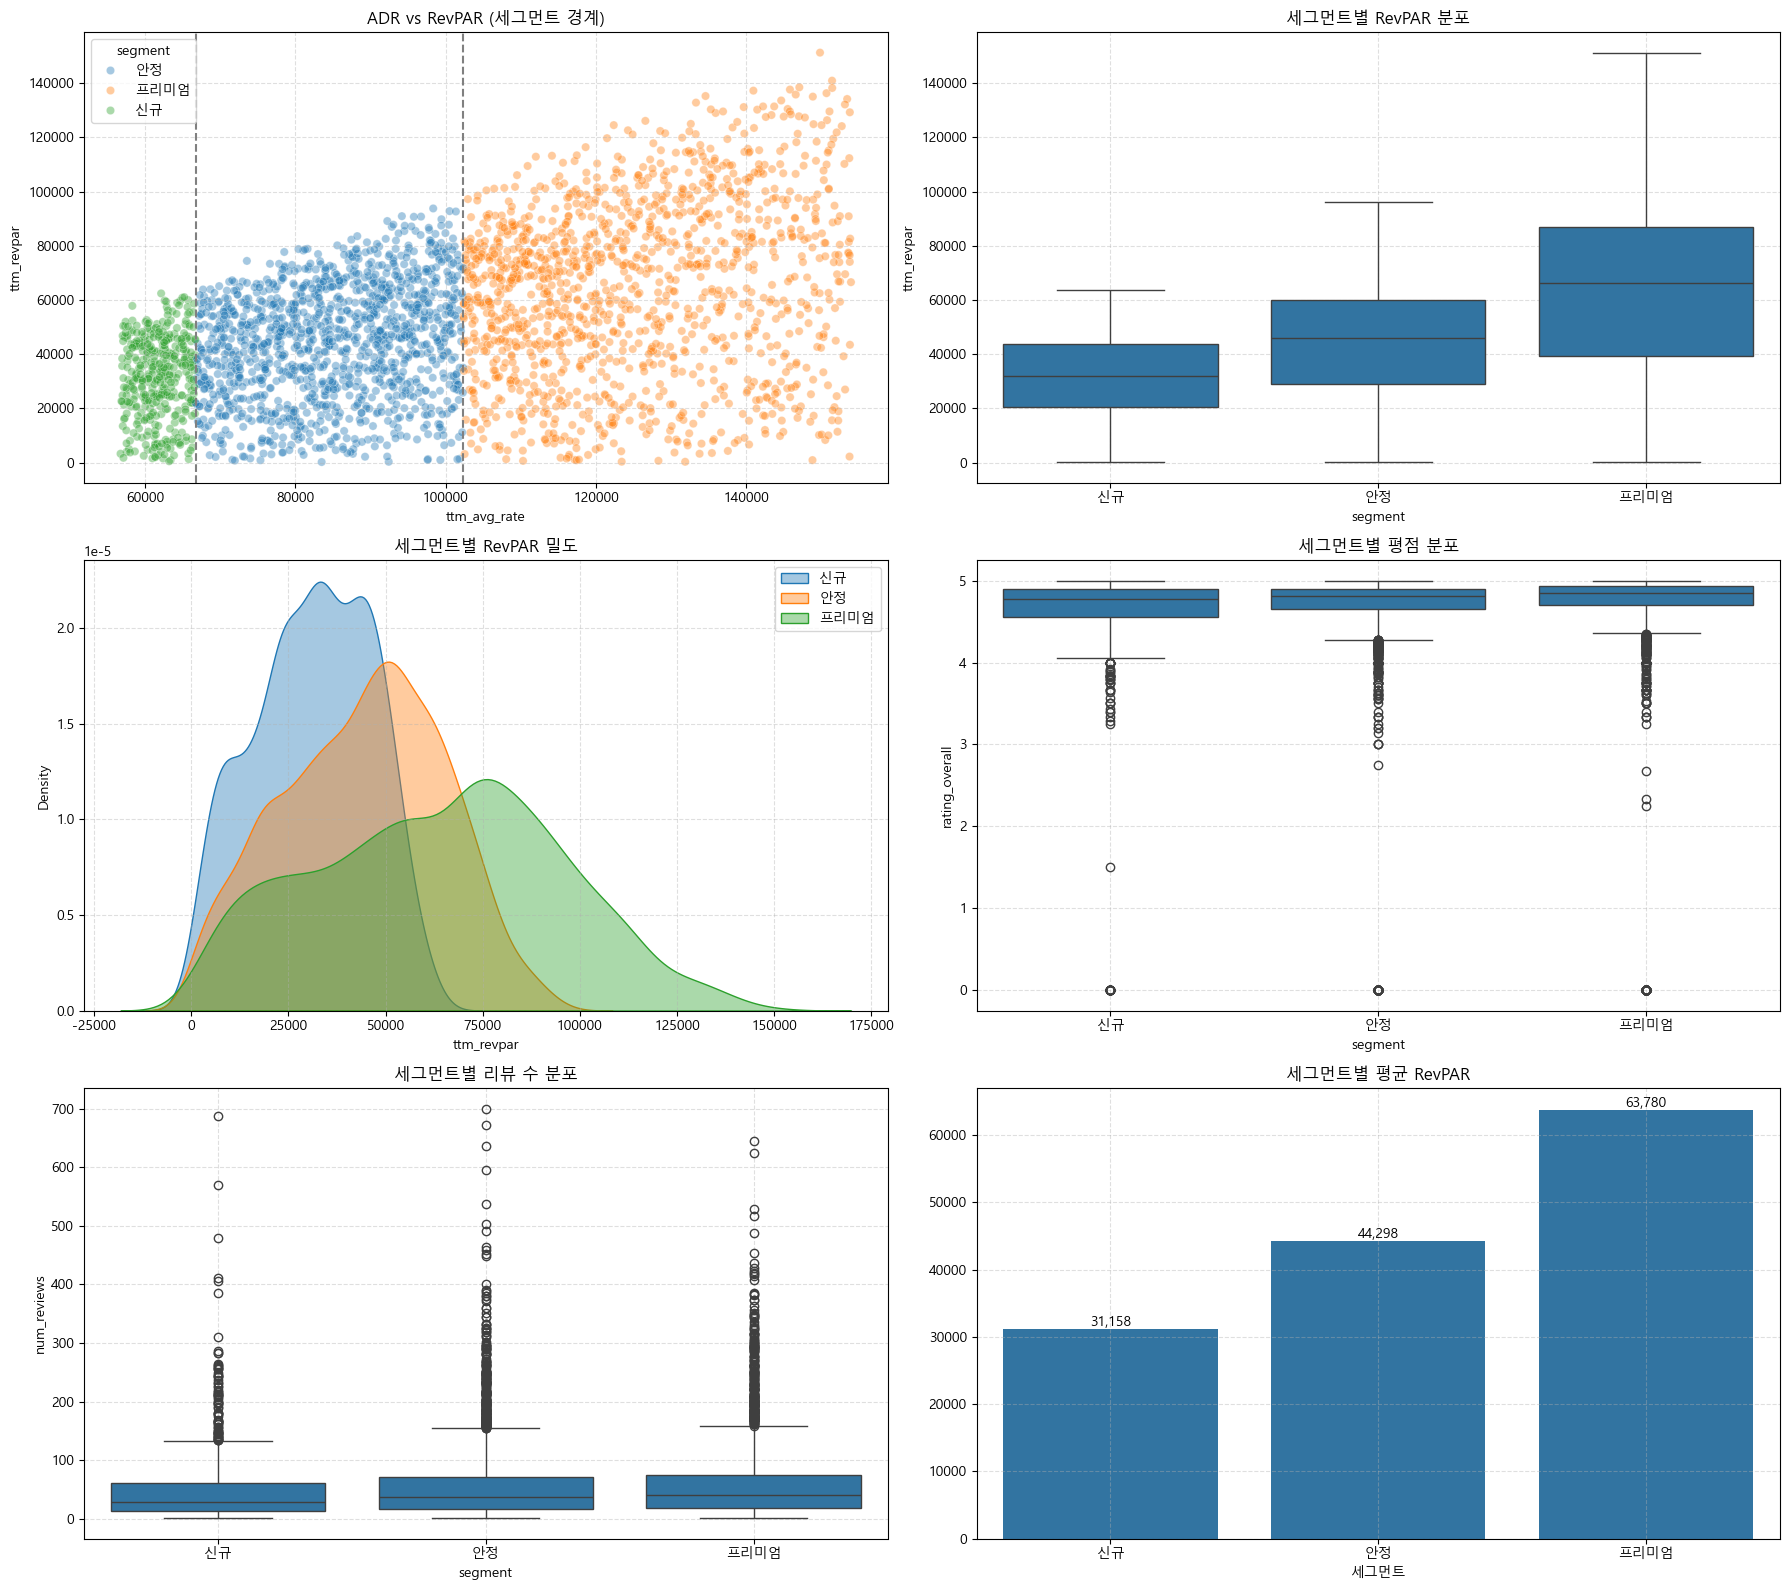

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['font.family'] = 'Malgun Gothic'  #한글,마이너스 코드 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False
# 시각화 전체 출력
# -----------------------------

# Active + Operating 필터
df = df[
    (df['refined_status'] == 'Active') &
    (df['operation_status'] == 'Operating')
].copy()

df = df.dropna(subset=['ttm_avg_rate', 'ttm_revpar'])

# 분위수 계산
p25 = np.percentile(df['ttm_avg_rate'], 25)
p50 = np.percentile(df['ttm_avg_rate'], 50)
p75 = np.percentile(df['ttm_avg_rate'], 75)

df["segment"] = "기타"

df.loc[(df["ttm_avg_rate"] >= p25*0.85) & (df["ttm_avg_rate"] < p25), "segment"] = "신규"
df.loc[(df["ttm_avg_rate"] >= p25) & (df["ttm_avg_rate"] < p50), "segment"] = "안정"
df.loc[(df["ttm_avg_rate"] >= p50) & (df["ttm_avg_rate"] <= p75), "segment"] = "프리미엄"

df_seg = df[df["segment"] != "기타"].copy()

order = ["신규", "안정", "프리미엄"]

fig, axes = plt.subplots(3, 2, figsize=(18, 16))

# 1️⃣ ADR vs RevPAR
sns.scatterplot(
    data=df_seg.sample(min(3000, len(df_seg)), random_state=42),
    x="ttm_avg_rate",
    y="ttm_revpar",
    hue="segment",
    alpha=0.4,
    ax=axes[0,0]
)
axes[0,0].axvline(p25, linestyle="--", color="gray")
axes[0,0].axvline(p50, linestyle="--", color="gray")
axes[0,0].set_title("ADR vs RevPAR (세그먼트 경계)")
axes[0,0].grid(True, linestyle='--', alpha=0.4)

# 2️⃣ RevPAR 박스플롯
sns.boxplot(data=df_seg, x="segment", y="ttm_revpar", order=order, ax=axes[0,1])
axes[0,1].set_title("세그먼트별 RevPAR 분포")
axes[0,1].grid(True, linestyle='--', alpha=0.4)

# 3️⃣ RevPAR KDE
for seg in order:
    sns.kdeplot(
        df_seg[df_seg["segment"]==seg]["ttm_revpar"],
        fill=True,
        label=seg,
        ax=axes[1,0],
        alpha=0.4
    )
axes[1,0].set_title("세그먼트별 RevPAR 밀도")
axes[1,0].legend()
axes[1,0].grid(True, linestyle='--', alpha=0.4)

# 4️⃣ 평점 분포
sns.boxplot(data=df_seg, x="segment", y="rating_overall", order=order, ax=axes[1,1])
axes[1,1].set_title("세그먼트별 평점 분포")
axes[1,1].grid(True, linestyle='--', alpha=0.4)

# 5️⃣ 리뷰 수 분포
sns.boxplot(data=df_seg, x="segment", y="num_reviews", order=order, ax=axes[2,0])
axes[2,0].set_title("세그먼트별 리뷰 수 분포")
axes[2,0].grid(True, linestyle='--', alpha=0.4)

# 6️⃣ 평균 RevPAR 비교
mean_rev = df_seg.groupby("segment")["ttm_revpar"].mean().reindex(order)

sns.barplot(
    x=mean_rev.index,
    y=mean_rev.values,
    ax=axes[2,1]
)
axes[2,1].set_title("세그먼트별 평균 RevPAR")
axes[2,1].set_xlabel("세그먼트")
axes[2,1].grid(True, linestyle='--', alpha=0.4)

for i, v in enumerate(mean_rev.values):
    axes[2,1].text(i, v, f"{int(v):,}", ha='center', va='bottom')

plt.tight_layout()
plt.show()

In [39]:
# Active + Operating 필터
df = df[
    (df['refined_status'] == 'Active') &
    (df['operation_status'] == 'Operating')
].copy()

# 필요한 컬럼만
cols = [
    'ttm_revpar',
    'ttm_avg_rate',
    'num_reviews',
    'rating_overall',
    'superhost'
]

df = df[cols].dropna().copy()

# superhost를 숫자로 변환 (True/False → 1/0)
df['superhost'] = df['superhost'].astype(int)

# 종속변수
y = df['ttm_revpar']

# 독립변수
X = df[['ttm_avg_rate', 'num_reviews', 'rating_overall', 'superhost']]

# 표준화 (변수 영향력 비교용)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled = pd.DataFrame(X_scaled, columns=X.columns)

# 상수항 추가
X_scaled = sm.add_constant(X_scaled)

# 회귀 실행
model = sm.OLS(y, X_scaled).fit()

print(model.summary())

NameError: name 'StandardScaler' is not defined